In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('/content/sales_data.csv')

In [3]:
df.head()

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie


In [4]:
from sklearn.preprocessing import StandardScaler

features = [
    "Sales_Amount",
    "Quantity_Sold",
    "Unit_Cost",
    "Unit_Price",
    "Discount"
]

X = df[features].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df.loc[X.index, "KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["Sales_Amount", "KMeans_Cluster"]].head())

   Sales_Amount  KMeans_Cluster
0       5053.97             1.0
1       4384.02             2.0
2       4631.23             1.0
3       2167.94             2.0
4       3750.20             1.0


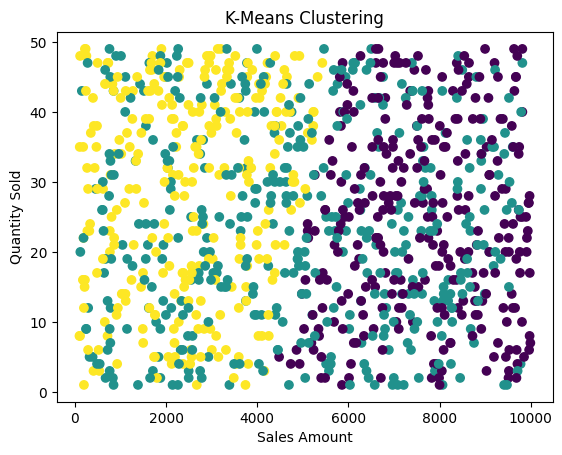

In [8]:
import matplotlib.pyplot as plt

plt.scatter(
    X["Sales_Amount"],
    X["Quantity_Sold"],
    c=df.loc[X.index, "KMeans_Cluster"]
)

plt.xlabel("Sales Amount")
plt.ylabel("Quantity Sold")
plt.title("K-Means Clustering")
plt.show()

In [9]:
from sklearn.preprocessing import StandardScaler

features = [
    "Sales_Amount",
    "Quantity_Sold",
    "Unit_Cost",
    "Unit_Price",
    "Discount"
]

X = df[features].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df.loc[X.index, "KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["Sales_Amount", "KMeans_Cluster"]].head())

   Sales_Amount  KMeans_Cluster
0       5053.97             1.0
1       4384.02             2.0
2       4631.23             1.0
3       2167.94             2.0
4       3750.20             1.0


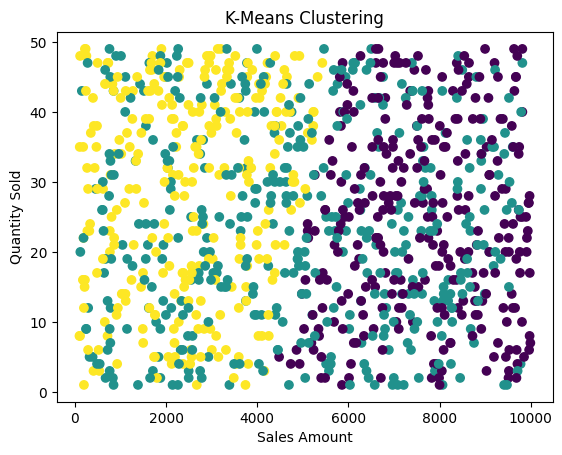

In [11]:
plt.scatter(
    X["Sales_Amount"],
    X["Quantity_Sold"],
    c=df.loc[X.index, "KMeans_Cluster"]
)

plt.xlabel("Sales Amount")
plt.ylabel("Quantity Sold")
plt.title("K-Means Clustering")
plt.show()

In [12]:
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(n_clusters=3)

df.loc[X.index, "Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print(df[["Sales_Amount", "Hierarchical_Cluster"]].head())

   Sales_Amount  Hierarchical_Cluster
0       5053.97                   1.0
1       4384.02                   0.0
2       4631.23                   2.0
3       2167.94                   0.0
4       3750.20                   1.0


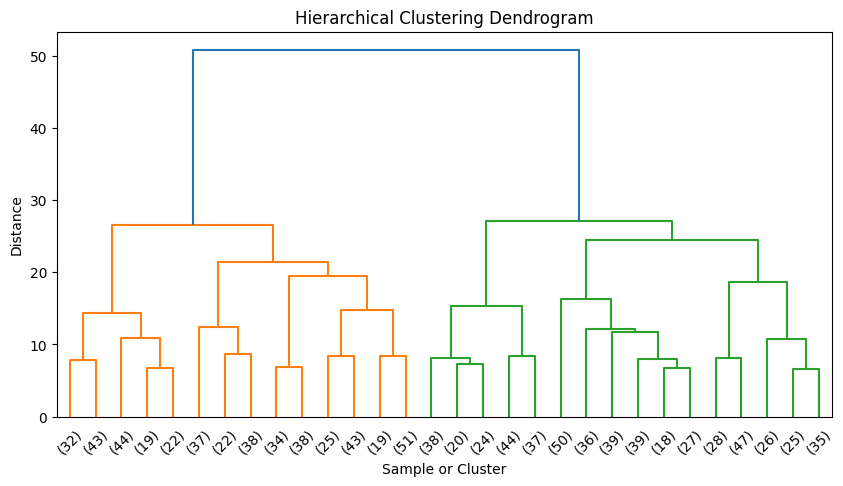

In [13]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=30)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Sample or Cluster")
plt.ylabel("Distance")
plt.show()

In [14]:
print(df[[
    "Sales_Amount",
    "KMeans_Cluster",
    "Hierarchical_Cluster"
]].head(10))

   Sales_Amount  KMeans_Cluster  Hierarchical_Cluster
0       5053.97             1.0                   1.0
1       4384.02             2.0                   0.0
2       4631.23             1.0                   2.0
3       2167.94             2.0                   0.0
4       3750.20             1.0                   1.0
5       3761.15             1.0                   2.0
6        618.31             2.0                   0.0
7       7698.92             0.0                   0.0
8       4223.39             1.0                   2.0
9       8239.58             0.0                   0.0
